# EDA: AI-судья по правилам D&D 5e (RAG по SRD 2014 и 2024)

**Чекпойнт 2, DL-трек (NLP).** Годовой проект «RAG-система / дообучение LLM под домен», уровень PRO.

**Задача проекта.** Система вопрос-ответ по правилам D&D 5e на русском языке со ссылками на разделы и с указанием версии правил (2014 или 2024). Корпус английский. Далее: сравнение RAG и LoRA, борьба с галлюцинациями, домашние правила (хоумрулы) стола.

**Цель EDA.** Понять данные настолько, чтобы принять решения о пайплайне: как резать корпус на чанки, какие метаданные и фильтры нужны, откуда брать вопросы для тестсета и какие риски заложить. Каждый раздел заканчивается выводом, сводка решений в конце.

## Вопросы к данным

1. Из чего состоят корпуса двух версий: какие типы сущностей, сколько, есть ли пропуски и ошибки?
2. Какой длины тексты? Подходит ли «одна сущность = один чанк»?
3. Насколько 2014 и 2024 отличаются друг от друга?
4. Какая доля реальных вопросов людей (Stack Exchange) покрыта SRD, и сколько из них пригодно для тестсета?
5. Какие выбросы и объекты вне домена есть в данных?
6. Что можно получить от самой простой модели (BM25) и чему это учит?
7. Какие риски (язык, версии, утечки, лицензии) надо учесть заранее?

In [1]:
import json, re, random, difflib, collections, html, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (8, 4), "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 90, "display.width", 140)

RAW = Path("data/raw")
FIG = Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
PALETTE = {"2014": "#4C8DF6", "2024": "#E8743B"}

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()

def norm(s):
    return re.sub(r"[^a-z0-9]+", " ", str(s).lower().replace("’", "'")).strip()

## 1. Источники данных

| Источник | Что это | Версия правил | Формат | Лицензия |
|---|---|---|---|---|
| SRD 5.1, Markdown (`gabrielrega/cc-srd5`) | Полный текст правил | 2014 | Markdown | CC BY 4.0 |
| SRD 5.2.1, PDF (D&D Beyond) → Markdown (`scripts/extract_srd_2024.py`) | Полный текст правил | 2024 | PDF → Markdown | CC BY 4.0 |
| Open5e API v2, документы `srd-2014`, `srd-2024` | Сущности: заклинания, монстры, классы и др. | обе | JSON | CC BY 4.0 |
| Дамп Stack Exchange `rpg.stackexchange.com` (апрель 2024) | Реальные вопросы и ответы людей | 2014 (тег `dnd-5e`) | XML → jsonl | CC BY-SA |

Скачивание воспроизводится скриптом `scripts/download_data.py`, извлечение PDF скриптом `scripts/extract_srd_2024.py`. Провенанс записан в `data/raw/MANIFEST.json`.

In [2]:
manifest = json.loads((RAW / "MANIFEST.json").read_text())
pd.DataFrame(manifest).T[["retrieved_at", "count", "license"]].head(30)

,retrieved_at,count,license
srd-5.1,2026-11-06T11:31:51+00:00,NaN,CC BY 4.0
open5e/2014/spells,2026-11-06T12:04:41+00:00,319,CC BY 4.0
open5e/2014/classes,2026-11-06T12:04:55+00:00,24,CC BY 4.0
open5e/2014/creatures,2026-11-06T12:05:16+00:00,325,CC BY 4.0
open5e/2014/items,2026-11-06T12:06:22+00:00,237,CC BY 4.0
open5e/2014/magicitems,2026-11-06T12:06:32+00:00,499,CC BY 4.0
open5e/2014/weapons,2026-11-06T12:06:32+00:00,37,CC BY 4.0
open5e/2014/armor,2026-11-06T12:06:34+00:00,12,CC BY 4.0
open5e/2014/feats,2026-11-06T12:06:34+00:00,1,CC BY 4.0
open5e/2014/backgrounds,2026-11-06T12:06:36+00:00,1,CC BY 4.0


## 2. Корпус: состав, пропуски, ошибки

In [3]:
ENDPOINTS = ["spells", "creatures", "classes", "species", "feats", "backgrounds",
             "items", "magicitems", "weapons", "armor", "rules"]
VERSIONS = ["2014", "2024"]

def load(version, ep):
    return json.loads((RAW / "open5e" / version / f"{ep}.json").read_text())

def collect(o):
    # весь текст сущности: поля desc / higher_level на любой глубине (описания черт, действий монстров и т.д.)
    out = []
    if isinstance(o, dict):
        for k, v in o.items():
            if k in ("document", "crossreferences"):
                continue
            if k in ("desc", "higher_level") and isinstance(v, str):
                out.append(v)
            else:
                out += collect(v)
    elif isinstance(o, list):
        for x in o:
            out += collect(x)
    return out

rows = []
raw_entities = {}
for v in VERSIONS:
    for ep in ENDPOINTS:
        data = load(v, ep)
        raw_entities[(v, ep)] = data
        for e in data:
            text = "\n".join(t for t in collect(e) if t.strip())
            rows.append({"version": v, "type": ep, "name": e["name"], "key": e["key"], "text": text,
                         "words": len(text.split())})
ent = pd.DataFrame(rows)
ent["norm"] = ent["name"].map(norm)
print(f"Всего сущностей: {len(ent)}")
cnt = ent.pivot_table(index="type", columns="version", values="name", aggfunc="count").loc[ENDPOINTS]
cnt

Всего сущностей: 3489


version,2014,2024
type,,
spells,319,339
creatures,325,331
classes,24,24
species,13,9
feats,1,17
backgrounds,1,4
items,237,203
magicitems,499,760
weapons,37,38


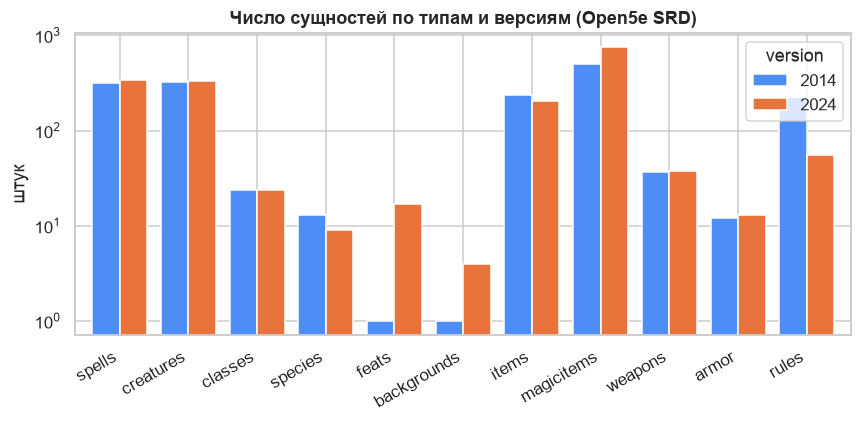

In [4]:
ax = cnt.plot.bar(color=[PALETTE["2014"], PALETTE["2024"]], width=0.8)
ax.set_title("Число сущностей по типам и версиям (Open5e SRD)"); ax.set_ylabel("штук"); ax.set_xlabel("")
ax.set_yscale("log"); plt.xticks(rotation=30, ha="right")
save("01_entities_by_type")

**Пропуски.** Проверяем две вещи: доля сущностей без текста (после сборки из `desc` / `higher_level`) и доля пустых полей в структурированных записях заклинаний и монстров.

In [5]:
empty_share = ent.assign(empty=ent["words"].eq(0)).pivot_table(index="type", columns="version", values="empty", aggfunc="mean").loc[ENDPOINTS]
print("Доля сущностей без текста:"); display((empty_share * 100).round(1))

def is_empty(v):
    return v is None or v == "" or v == [] or v == {}

for typ in ["spells", "creatures"]:
    for v in VERSIONS:
        df = pd.DataFrame(raw_entities[(v, typ)])
        share = df.map(is_empty).mean().sort_values(ascending=False)
        print(f"\n{typ} {v}: поля с пустыми значениями (доля)")
        print(share[share > 0].round(3).head(8).to_string())

Доля сущностей без текста:


version,2014,2024
type,,
spells,0.0,0.3
creatures,0.3,0.3
classes,0.0,0.0
species,0.0,0.0
feats,0.0,0.0
backgrounds,0.0,0.0
items,0.0,0.0
magicitems,0.0,0.0
weapons,10.8,0.0



spells 2014: поля с пустыми значениями (доля)
damage_roll             0.809
damage_types            0.809
higher_level            0.687
saving_throw_ability    0.630
material_specified      0.426
classes                 0.006

spells 2024: поля с пустыми значениями (доля)
material_cost           1.000
damage_types            0.684
damage_roll             0.649
casting_options         0.643
higher_level            0.640
saving_throw_ability    0.622
material_specified      0.445
desc                    0.003

creatures 2014: поля с пустыми значениями (доля)
proficiency_bonus    1.000
creaturesets         0.972
illustration         0.963
saving_throws        0.692
skill_bonuses        0.397
armor_detail         0.345
traits               0.178
environments         0.009

creatures 2024: поля с пустыми значениями (доля)
subcategory      1.000
illustration     1.000
environments     1.000
creaturesets     1.000
traits           0.384
skill_bonuses    0.347
actions          0.003
armor_det

In [6]:
# Проверки на ошибочные значения
checks = []
def chk(name, n):
    checks.append({"проверка": name, "нашлось": int(n)})

for v in VERSIONS:
    sp = pd.DataFrame(raw_entities[(v, "spells")])
    chk(f"{v}: заклинания с уровнем вне 0..9", (~sp["level"].between(0, 9)).sum())
    cr = pd.DataFrame(raw_entities[(v, "creatures")])
    chk(f"{v}: монстры с hit_points <= 0", (pd.to_numeric(cr["hit_points"], errors="coerce") <= 0).sum())
    chk(f"{v}: монстры без challenge_rating", cr["challenge_rating"].isna().sum() if "challenge_rating" in cr else -1)
    e = ent[ent.version == v]
    chk(f"{v}: дубликаты имён внутри типа", e.duplicated(["type", "norm"]).sum())
    chk(f"{v}: тексты с символом замены U+FFFD", e["text"].str.contains("�").sum())
    chk(f"{v}: тексты с неразрывным пробелом", e["text"].str.contains(" ").sum())
    chk(f"{v}: тексты с разметкой Markdown (** или таблица |)", e["text"].str.contains(r"\*\*|^\|", regex=True, flags=re.M).sum())
    chk(f"{v}: тексты короче 20 символов, но не пустые", ((e["text"].str.len() > 0) & (e["text"].str.len() < 20)).sum())
pd.DataFrame(checks)

,проверка,нашлось
0,2014: заклинания с уровнем вне 0..9,0
1,2014: монстры с hit_points <= 0,0
2,2014: монстры без challenge_rating,0
3,2014: дубликаты имён внутри типа,20
4,2014: тексты с символом замены U+FFFD,0
5,2014: тексты с неразрывным пробелом,0
6,2014: тексты с разметкой Markdown (** или таблица |),241
7,"2014: тексты короче 20 символов, но не пустые",57
8,2024: заклинания с уровнем вне 0..9,0
9,2024: монстры с hit_points <= 0,0


**Вывод по разделу 2.** См. сводку в конце. Главное: структурированные сущности Open5e почти не содержат ошибок; проблемы не в «грязных значениях», а в неполноте (разный охват типов между версиями, отсутствие текста у части сущностей).

## 3. Длины текстов и разбиение на чанки

Для эмбеддингов важна длина в токенах. Токенайзер BGE-M3 пока не подключаем, оцениваем токены как `слова × 1.35` (грубое правило для английского, проверим позже). Практическое окно эмбеддера 512 токенов ≈ **380 слов**.

count    50%     90%     99%     max  доля > окна 512 ток., %
type       version                                                               
classes    2014      24.0  664.0  1384.0  2176.0  2382.0                     66.7
           2024      24.0  668.0  1824.0  2664.0  2856.0                     62.5
creatures  2014     324.0  112.0   314.0   606.0   853.0                      7.4
           2024     330.0   87.0   226.0   396.0   595.0                      1.8
feats      2014       1.0   70.0    70.0    70.0    70.0                      0.0
           2024      17.0   47.0    81.0   137.0   146.0                      0.0
items      2014     237.0   27.0    95.0   172.0   301.0                      0.0
           2024     203.0   21.0   124.0   213.0   696.0                      0.5
magicitems 2014     499.0   87.0   223.0   558.0   963.0                      2.4
           2024     760.0  142.0   249.0   568.0  1467.0                      2.2
rules      2014     227.0  121.0   305.0   826.0   921.0                      7.9
           2024      56.0  142.0   502.0   712.0   727.0                     17.9
species    2014      13.0  228.0   312.0   430.0   445.0                      7.7
           2024       9.0  228.0   323.0   331.0   332.0                      0.0
spells     2014     319.0  119.0   275.0   535.0   702.0                      5.6
           2024     338.0  102.0   226.0   480.0   625.0                      1.8

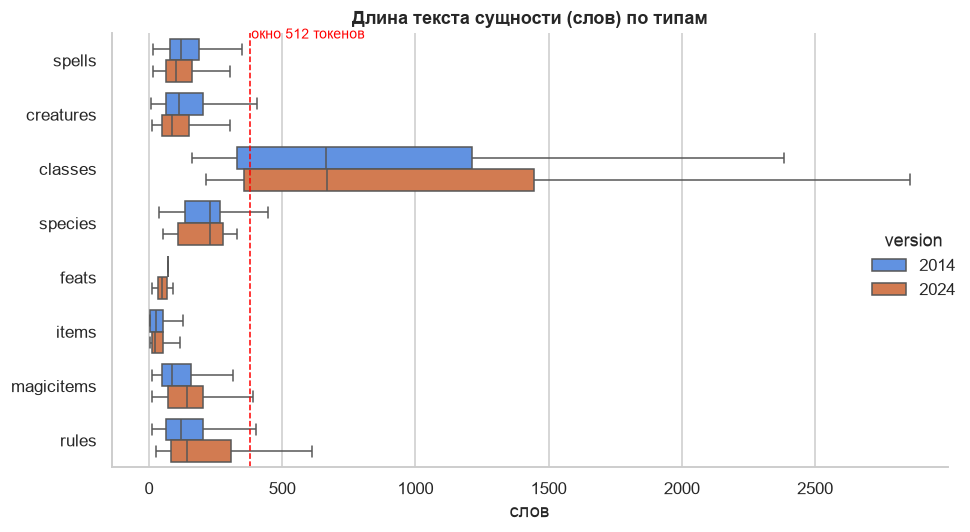

In [7]:
TOK = 1.35
WINDOW_WORDS = int(512 / TOK)
text_types = ["spells", "creatures", "classes", "species", "feats", "magicitems", "items", "rules"]
d = ent[ent.type.isin(text_types) & (ent.words > 0)]

q = d.groupby(["type", "version"])["words"].describe(percentiles=[.5, .9, .99])[["count", "50%", "90%", "99%", "max"]].round(0)
q["доля > окна 512 ток., %"] = d.groupby(["type", "version"])["words"].apply(lambda s: (s > WINDOW_WORDS).mean() * 100).round(1)
display(q)

g = sns.catplot(data=d, x="words", y="type", hue="version", kind="box", palette=PALETTE, showfliers=False, height=5, aspect=1.6)
g.ax.axvline(WINDOW_WORDS, color="red", ls="--", lw=1); g.ax.text(WINDOW_WORDS + 5, -0.4, "окно 512 токенов", color="red", fontsize=9)
g.ax.set_title("Длина текста сущности (слов) по типам"); g.ax.set_xlabel("слов"); g.ax.set_ylabel("")
save("02_entity_lengths")

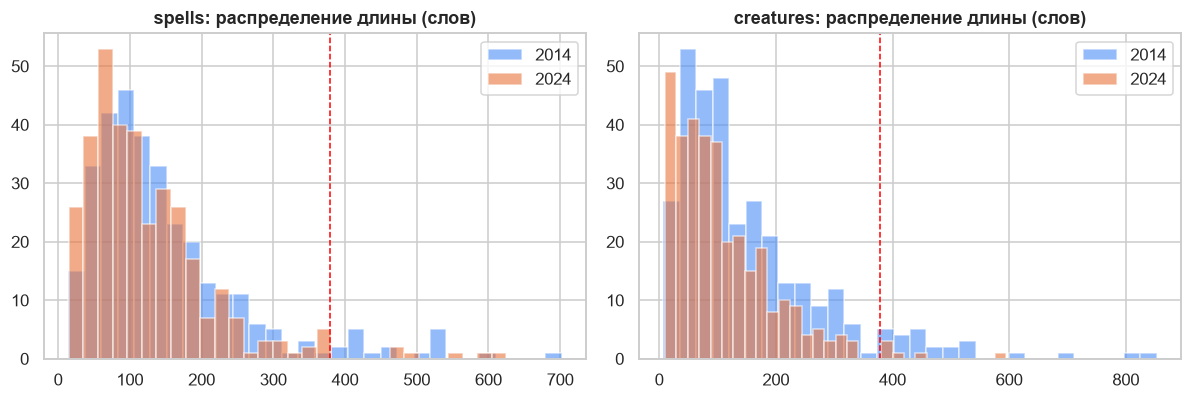

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, typ in zip(axes, ["spells", "creatures"]):
    for v in VERSIONS:
        ax.hist(d[(d.type == typ) & (d.version == v)]["words"], bins=30, alpha=.6, color=PALETTE[v], label=v)
    ax.axvline(WINDOW_WORDS, color="red", ls="--", lw=1)
    ax.set_title(f"{typ}: распределение длины (слов)"); ax.legend()
save("03_len_hist")

### Длины разделов в Markdown-корпусах (полный текст правил)

Здесь «чанк» естественный: текст между заголовками.

In [9]:
def md_sections(path, skip_first_lines=0):
    secs, cur = [], None
    for i, line in enumerate(Path(path).read_text().split("\n")):
        m = re.match(r"^(#{1,6}) (.*)", line)
        if m:
            if cur: secs.append(cur)
            cur = {"level": len(m[1]), "title": re.sub(r"\s*\{#.*\}", "", m[2]).strip(" *_"), "words": 0, "table_lines": 0, "lines": 0}
        elif cur is not None:
            cur["words"] += len(line.split()); cur["lines"] += 1; cur["table_lines"] += line.startswith("|")
    if cur: secs.append(cur)
    return pd.DataFrame(secs)

sec14 = md_sections(RAW / "srd-5.1" / "cc-srd5.md").assign(version="2014")
sec24 = md_sections("data/interim/srd_2024/srd_5.2.1.md").assign(version="2024")
sec = pd.concat([sec14, sec24], ignore_index=True)

summary = sec.groupby("version").agg(разделов=("title", "count"), слов_всего=("words", "sum"),
                                     медиана_слов=("words", "median"), p90=("words", lambda s: s.quantile(.9)),
                                     макс=("words", "max"))
summary["разделов > окна 512 ток., %"] = sec.groupby("version")["words"].apply(lambda s: (s > WINDOW_WORDS).mean() * 100).round(1)
display(summary.round(0))
display(sec.pivot_table(index="level", columns="version", values="title", aggfunc="count").fillna(0).astype(int).rename_axis("уровень заголовка"))

,разделов,слов_всего,медиана_слов,p90,макс,"разделов > окна 512 ток., %"
version,,,,,,
2014,2098,266858,99.0,252.0,3728,4.0
2024,2856,223854,57.0,169.0,1167,1.0


version,2014,2024
уровень заголовка,,
1,17,13
2,106,642
3,626,1816
4,987,385
5,362,0


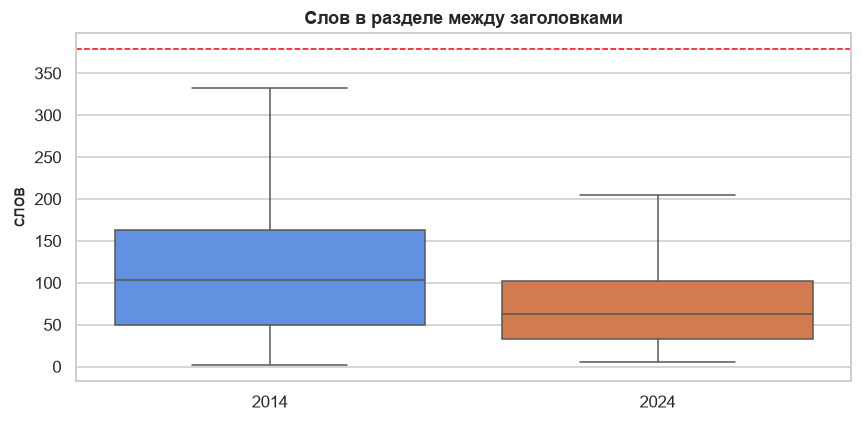

,version,level,title,words
1063,2014,2,Adventuring Gear,3728
1145,2014,3,Deck of Many Things,1266
3615,2024,3,Mysterious Deck,1167
1064,2014,2,Tools,1108
457,2014,4,Spellcasting,1008
404,2014,4,Overchannel,963
3744,2024,3,Wand of Wonder,891
2248,2024,2,Trinkets,835
3568,2024,3,Giant Fly,727
3597,2024,3,Ioun Stone,702


In [10]:
ax = sns.boxplot(data=sec[sec.words > 0], x="version", y="words", palette=PALETTE, showfliers=False)
ax.axhline(WINDOW_WORDS, color="red", ls="--", lw=1); ax.set_title("Слов в разделе между заголовками"); ax.set_xlabel(""); ax.set_ylabel("слов")
save("04_section_lengths")
longest = sec.sort_values("words", ascending=False).groupby("version").head(5)[["version", "level", "title", "words"]]
longest

**Вывод по разделу 3.** См. сводку: заклинания и большинство сущностей короткие, поэтому «одна сущность = один чанк» работает. Длинные объекты (классы, часть монстров и разделы с таблицами) надо делить по подзаголовкам.

## 4. Структура и «грязные» записи

Смотрим, что мешает чанкингу и поиску: ссылки и якоря в Markdown 2014, таблицы, остатки вёрстки в 2024.

In [11]:
txt14 = (RAW / "srd-5.1" / "cc-srd5.md").read_text()
txt24 = Path("data/interim/srd_2024/srd_5.2.1.md").read_text()
def noise(t):
    return {
        "строк": t.count("\n"),
        "якорей {#...}": len(re.findall(r"\{#[^}]+\}", t)),
        "Markdown-ссылок [..](..)": len(re.findall(r"\[[^\]]+\]\([^)]+\)", t)),
        "таблиц в Markdown-синтаксисе (строки с |)": len(re.findall(r"^\|", t, flags=re.M)),
        "таблиц в виде HTML (<table>)": len(re.findall(r"<table", t)),
        "тегов HTML всего": len(re.findall(r"</?[a-z]+[^>]*>", t)),
        "слов с переносом 'ab- cd'": len(re.findall(r"[a-z]{3}- [a-z]{3}", t)),
        "строк с 'System Reference Document' (колонтитул)": t.count("System Reference Document 5.2.1"),
    }
pd.DataFrame({"2014 (SRD 5.1 MD)": noise(txt14), "2024 (SRD 5.2.1 из PDF)": noise(txt24)})

,2014 (SRD 5.1 MD),2024 (SRD 5.2.1 из PDF)
строк,46413,23666
якорей {#...},124,0
Markdown-ссылок [..](..),3539,0
таблиц в Markdown-синтаксисе (строки с |),6,2993
таблиц в виде HTML (<table>),455,0
тегов HTML всего,30850,528
слов с переносом 'ab- cd',1,1
строк с 'System Reference Document' (колонтитул),0,0


In [12]:
random.seed(SEED)
for v, df_ in [("2014", sec14), ("2024", sec24)]:
    print(f"===== случайные разделы {v} (seed={SEED}) =====")
    for _, r in df_[df_.words > 30].sample(4, random_state=SEED).iterrows():
        print(f"- [{'#' * r.level}] {r.title!r}: {r.words} слов, строк таблиц {r.table_lines}")

===== случайные разделы 2014 (seed=42) =====
- [###] 'Manual of Bodily Health': 64 слов, строк таблиц 0
- [###] 'Contests': 233 слов, строк таблиц 0
- [##] 'Movement and Position': 104 слов, строк таблиц 0
- [###] 'Horseshoes of a Zephyr': 93 слов, строк таблиц 0
===== случайные разделы 2024 (seed=42) =====
- [###] 'Speed': 33 слов, строк таблиц 0
- [###] 'Cure Wounds': 53 слов, строк таблиц 0
- [###] 'Armor of Invulnerability': 64 слов, строк таблиц 0
- [##] 'Spy': 92 слов, строк таблиц 0


In [13]:
# Известный артефакт извлечения из PDF: ability-таблица в статблоках
m = re.search(r"\*\*S tr\*\*.*", txt24)
print("Пример артефакта (малые заглавные в PDF):", m.group(0)[:120] if m else "не найден")

Пример артефакта (малые заглавные в PDF): **S tr** 17 +3 +3 **d ex** 13 +1 +1 **c on** 15 +2 +2 **i nt** 4 −3 −3 **W iS** 14 +2 +2 **c hA** 3 −4 −4


**Вывод по разделу 4.** Markdown 2014 содержит якоря и ссылки (шум для эмбеддингов, надо чистить); извлечённый из PDF Markdown 2024 чище по ссылкам, но содержит артефакты в таблицах характеристик монстров. Для характеристик монстров 2024 надёжнее брать Open5e, для текста правил PDF.

## 5. Сравнение версий 2014 и 2024

Основа проекта: **одна сущность существует в двух версиях с разными правилами**. Измеряем, насколько они различаются, на заклинаниях, монстрах и классах.

In [14]:
def get(e, field):
    v = e.get(field)
    return v.get("name") if isinstance(v, dict) else v

def pair_stats(typ):
    a = ent[(ent.type == typ) & (ent.version == "2014")].drop_duplicates("norm").set_index("norm")
    b = ent[(ent.type == typ) & (ent.version == "2024")].drop_duplicates("norm").set_index("norm")
    common = a.index.intersection(b.index)
    out = []
    for n in common:
        ta, tb = re.findall(r"[a-z0-9]+", a.loc[n, "text"].lower()), re.findall(r"[a-z0-9]+", b.loc[n, "text"].lower())
        if not ta or not tb:  # у сущности нет текста в одной из версий (пробел в данных Open5e)
            continue
        out.append({"norm": n, "name": a.loc[n, "name"], "ratio": difflib.SequenceMatcher(None, ta, tb, autojunk=False).ratio(),
                    "w14": len(ta), "w24": len(tb)})
    return pd.DataFrame(out), sorted(a.index.difference(b.index)), sorted(b.index.difference(a.index))

res = {}
for typ in ["spells", "creatures", "classes"]:
    df_, only14, only24 = pair_stats(typ)
    res[typ] = (df_, only14, only24)
    n14 = (ent[(ent.type == typ) & (ent.version == '2014')]).shape[0]; n24 = (ent[(ent.type == typ) & (ent.version == '2024')]).shape[0]
    same = (df_.ratio >= .9).mean() * 100; minor = ((df_.ratio < .9) & (df_.ratio >= .6)).mean() * 100; major = (df_.ratio < .6).mean() * 100
    print(f"{typ}: 2014={n14}, 2024={n24}, общих по имени={len(df_)}, только 2014={len(only14)}, только 2024={len(only24)}")
    print(f"   схожесть текста (слова, без регистра и пунктуации): медиана {df_.ratio.median():.2f}; "
          f"почти без изменений (>=0.9) {same:.1f}%, переформулировано (0.6..0.9) {minor:.1f}%, существенно переписано (<0.6) {major:.1f}%")

spells: 2014=319, 2024=339, общих по имени=316, только 2014=2, только 2024=22
   схожесть текста (слова, без регистра и пунктуации): медиана 0.70; почти без изменений (>=0.9) 15.2%, переформулировано (0.6..0.9) 56.0%, существенно переписано (<0.6) 28.8%
creatures: 2014=325, 2024=331, общих по имени=283, только 2014=42, только 2024=48
   схожесть текста (слова, без регистра и пунктуации): медиана 0.39; почти без изменений (>=0.9) 0.0%, переформулировано (0.6..0.9) 16.3%, существенно переписано (<0.6) 83.7%


classes: 2014=24, 2024=24, общих по имени=20, только 2014=4, только 2024=4
   схожесть текста (слова, без регистра и пунктуации): медиана 0.28; почти без изменений (>=0.9) 0.0%, переформулировано (0.6..0.9) 0.0%, существенно переписано (<0.6) 100.0%


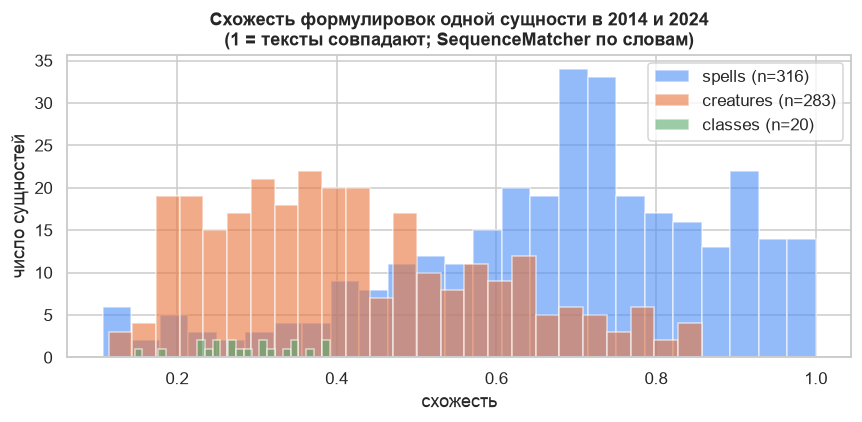

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
for typ, color in zip(["spells", "creatures", "classes"], ["#4C8DF6", "#E8743B", "#5BAA6A"]):
    ax.hist(res[typ][0].ratio, bins=25, alpha=.6, label=f"{typ} (n={len(res[typ][0])})", color=color)
ax.set_title("Схожесть формулировок одной сущности в 2014 и 2024\n(1 = тексты совпадают; SequenceMatcher по словам)")
ax.set_xlabel("схожесть"); ax.set_ylabel("число сущностей"); ax.legend()
save("05_version_similarity")

In [16]:
sp_df = res["spells"][0].sort_values("ratio")
print("10 заклинаний с наименьшей схожестью текста:"); display(sp_df.head(10)[["name", "ratio", "w14", "w24"]].round(2))
sim = res["spells"][0].set_index("norm").ratio
print(f"Схожесть формулировок: Fireball {sim['fireball']:.2f} (правило то же, текст переписан), Counterspell {sim['counterspell']:.2f} (правило изменилось)")
print("Counterspell:")
for v in VERSIONS:
    t = ent[(ent.version == v) & (ent.norm == "counterspell")].iloc[0]["text"]
    print(f"  [{v}] {t[:330]}")
print("\nСлова-названия, которых нет в другой версии (заклинания):")
print("  только 2014:", res["spells"][1]); print("  только 2024:", res["spells"][2])

10 заклинаний с наименьшей схожестью текста:


,name,ratio,w14,w24
55,Conjure Minor Elementals,0.11,182,80
56,Conjure Woodland Beings,0.11,184,111
51,Conjure Animals,0.12,199,158
297,True Strike,0.12,47,86
58,Contagion,0.13,284,132
11,Antimagic Field,0.14,458,126
52,Conjure Celestial,0.14,132,148
133,Giant Insect,0.16,137,162
264,Sleep,0.19,165,112
53,Conjure Elemental,0.19,218,158


Схожесть формулировок: Fireball 0.78 (правило то же, текст переписан), Counterspell 0.34 (правило изменилось)
Counterspell:
  [2014] You attempt to interrupt a creature in the process of casting a spell. If the creature is casting a spell of 3rd level or lower, its spell fails and has no effect. If it is casting a spell of 4th level or higher, make an ability check using your spellcasting ability. The DC equals 10 + the spell's level. On a success, the creatu
  [2024] You attempt to interrupt a creature in the process of casting a spell. The creature makes a Constitution saving throw. On a failed save, the spell dissipates with no effect, and the action, Bonus Action, or Reaction used to cast it is wasted. If that spell was cast with a spell slot, the slot isn't expended.

Слова-названия, которых нет в другой версии (заклинания):
  только 2014: ['branding smite', 'feeblemind']
  только 2024: ['aura of life', 'befuddlement', 'charm monster', 'chromatic orb', 'dissonant whispers', 'divin

In [17]:
# Изменились ли атрибуты заклинаний (уровень, школа, концентрация, ритуал, время сотворения)
sp = {v: {norm(e["name"]): e for e in raw_entities[(v, "spells")]} for v in VERSIONS}
fields = ["level", "school", "concentration", "ritual", "casting_time", "duration", "range_text"]
rows = []
for n in set(sp["2014"]) & set(sp["2024"]):
    r = {"name": sp["2014"][n]["name"]}
    for f in fields:
        r[f] = get(sp["2014"][n], f) != get(sp["2024"][n], f)
    rows.append(r)
chg = pd.DataFrame(rows)
display((chg[fields].mean() * 100).round(1).rename("доля заклинаний, где поле изменилось, %").to_frame())

,"доля заклинаний, где поле изменилось, %"
level,0.0
school,7.6
concentration,2.8
ritual,0.0
casting_time,8.2
duration,6.0
range_text,5.4


**Вывод по разделу 5.** См. сводку: значительная доля общих заклинаний и монстров имеет заметно разный текст, поэтому смешение версий реальная угроза, а не теоретическая. Версия должна быть метаданными чанка, фильтром при поиске и параметром запроса. Список существенно изменённых сущностей готовая основа для вопросов категории «различия версий».

## 6. Реальные вопросы людей (Stack Exchange)

Единственный источник вопросов, заданных людьми. Разбираем объём, качество, охват SRD и выбросы.

In [18]:
se = pd.read_json("data/interim/se_questions.jsonl", lines=True)
se["created"] = pd.to_datetime(se["created"])
strip = lambda h: re.sub(r"\s+", " ", html.unescape(re.sub(r"<[^>]+>", " ", h or ""))).strip()
se["q_text"] = (se["title"] + ". " + se["body"].map(strip))
se["a_text"] = se["accepted_answer"].map(lambda x: strip(x) if isinstance(x, str) else "")
se["q_words"] = se["q_text"].str.split().str.len(); se["a_words"] = se["a_text"].str.split().str.len()
se["has_accepted"] = se["a_text"].str.len() > 0
se["year"] = se["created"].dt.year

print(f"Вопросов с тегом dnd-5e: {len(se)}; с принятым ответом: {se.has_accepted.sum()} ({se.has_accepted.mean()*100:.1f}%)")
print(f"Период: {se.created.min().date()} .. {se.created.max().date()}")
print("Версия 2024 в тегах:", se.tags.map(lambda t: any('2024' in x for x in t)).sum(), "вопросов; тегов dnd-5e-2014/2024 в дампе нет")
display(se[["score", "q_words", "a_words"]].describe(percentiles=[.5, .9, .99]).round(1))

Вопросов с тегом dnd-5e: 22325; с принятым ответом: 14427 (64.6%)
Период: 2012-01-09 .. 2024-03-30
Версия 2024 в тегах: 0 вопросов; тегов dnd-5e-2014/2024 в дампе нет


,score,q_words,a_words
count,22325.0,22325.0,22325.0
mean,10.7,181.7,193.6
std,11.1,170.8,258.0
min,-19.0,12.0,0.0
50%,8.0,139.0,125.0
90%,22.0,342.0,487.0
99%,52.0,771.5,1168.0
max,246.0,4922.0,3628.0


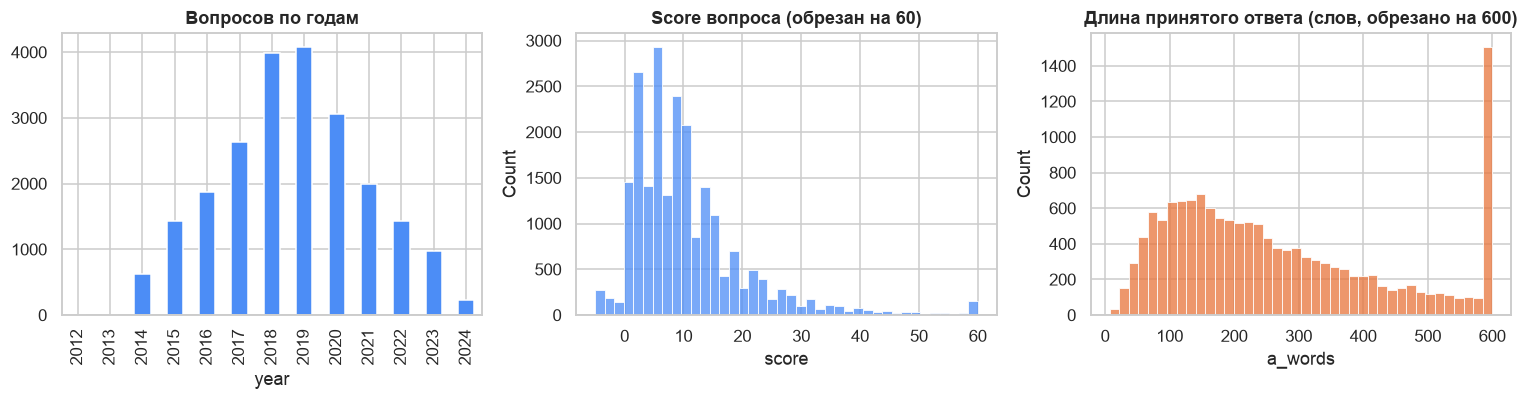

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
yr = se.groupby("year").size(); yr.plot.bar(ax=axes[0], color="#4C8DF6"); axes[0].set_title("Вопросов по годам")
sns.histplot(se.score.clip(-5, 60), bins=40, ax=axes[1], color="#4C8DF6"); axes[1].set_title("Score вопроса (обрезан на 60)")
sns.histplot(se[se.has_accepted].a_words.clip(0, 600), bins=40, ax=axes[2], color="#E8743B"); axes[2].set_title("Длина принятого ответа (слов, обрезано на 600)")
save("06_se_overview")

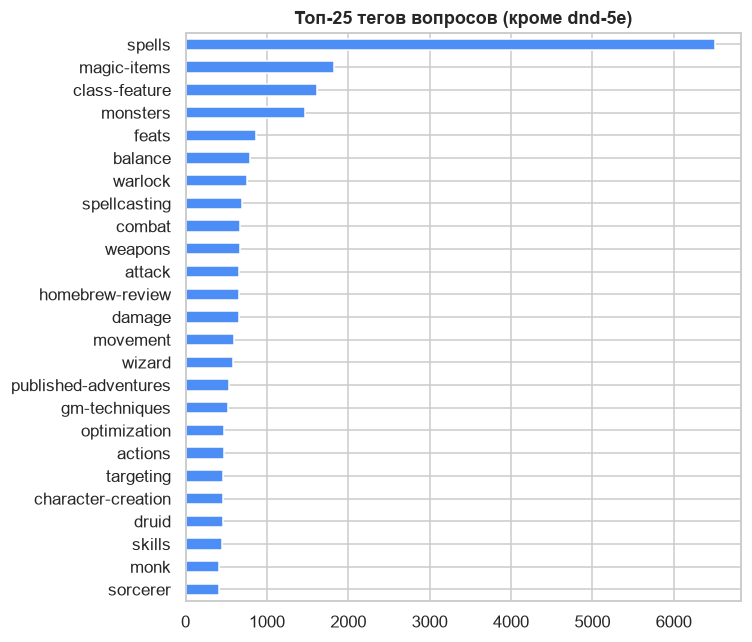

In [20]:
# Темы: самые частые теги
tag_counts = collections.Counter(t for tags in se.tags for t in tags if t != "dnd-5e")
top = pd.Series(tag_counts).sort_values(ascending=False).head(25)
ax = top[::-1].plot.barh(color="#4C8DF6", figsize=(7, 6)); ax.set_title("Топ-25 тегов вопросов (кроме dnd-5e)")
save("07_se_tags")

### Покрытие SRD: сколько вопросов можно отвечать по нашему корпусу

Прокси-оценка: в вопросе упоминается название сущности SRD (заклинание, монстр, класс, черта, вид). Это оценка приблизительная. Короткие названия вроде *Light*, *Aid*, *Fly* совпадают с обычными словами и завышают результат, поэтому даём два варианта:
- **широкая** (любое название длиной ≥ 4 символов), верхняя оценка;
- **строгая** (названия из ≥ 2 слов или ≥ 8 символов), оценка ближе к нижней.

Отдельно считаем долю вопросов про платные книги и сеттинги (признак «не SRD»).

In [21]:
names = set()
for v in VERSIONS:
    for ep in ["spells", "creatures", "classes", "feats", "species"]:
        names |= {e["name"] for e in raw_entities[(v, ep)] if e["name"]}
names = {n.lower().replace("’", "'") for n in names}
broad = sorted((n for n in names if len(n) >= 4), key=len, reverse=True)
strict = sorted((n for n in names if len(n.split()) >= 2 or len(n) >= 8), key=len, reverse=True)
rx = lambda lst: re.compile(r"\b(?:" + "|".join(re.escape(n) for n in lst) + r")\b")
rx_b, rx_s = rx(broad), rx(strict)
low = se["q_text"].str.lower().str.replace("’", "'")
se["cov_broad"] = low.map(lambda t: bool(rx_b.search(t)))
se["cov_strict"] = low.map(lambda t: bool(rx_s.search(t)))
se["cov_title_strict"] = se["title"].str.lower().str.replace("’", "'").map(lambda t: bool(rx_s.search(t)))

rule_terms = ["opportunity attack", "grapple", "grappled", "shove", "bonus action", "reaction", "advantage", "disadvantage",
              "saving throw", "death save", "concentration", "initiative", "short rest", "long rest", "cover", "surprise",
              "sneak attack", "hit points", "armor class", "proficiency", "spell slot", "ability check", "attack roll",
              "blinded", "charmed", "deafened", "exhaustion", "frightened", "incapacitated", "invisible", "paralyzed",
              "petrified", "poisoned", "prone", "restrained", "stunned", "unconscious", "critical hit", "temporary hit points"]
rx_t = re.compile(r"\b(?:" + "|".join(re.escape(t) for t in rule_terms) + r")\b")
se["rule_term"] = low.map(lambda t: bool(rx_t.search(t)))
se["in_domain"] = se["cov_strict"] | se["rule_term"]
books = r"xanathar|tasha|volo|mordenkainen|fizban|strixhaven|sword coast|eberron|ravnica|theros|spelljammer|van richten|wildemount|unearthed arcana|\bua\b|acquisitions inc|candlekeep|wild beyond|ghosts of saltmarsh|rime of the frostmaiden|curse of strahd|lost mine|waterdeep|icewind dale|tomb of annihilation|out of the abyss|princes of the apocalypse"
se["paid_book"] = low.str.contains(books, regex=True)
se["homebrew"] = se.tags.map(lambda t: any(x in t for x in ["homebrew", "game-balance", "character-creation", "campaign-design", "worldbuilding"]))

cov = pd.DataFrame({
    "доля, %": [se.cov_broad.mean()*100, se.cov_strict.mean()*100, se.cov_title_strict.mean()*100,
                se.rule_term.mean()*100, se.in_domain.mean()*100, se.paid_book.mean()*100, se.homebrew.mean()*100]
}, index=["упоминает сущность SRD (широкая оценка)", "упоминает сущность SRD (строгая оценка)",
          "сущность SRD в заголовке (строгая оценка)", "упоминает термин механики (состояние, спасбросок и т.п.)",
          "в домене правил: сущность SRD или термин механики", "упоминает платные книги / сеттинги",
          "теги homebrew / баланс / создание / кампания"]).round(1)
display(cov)

,"доля, %"
упоминает сущность SRD (широкая оценка),77.4
упоминает сущность SRD (строгая оценка),51.4
сущность SRD в заголовке (строгая оценка),23.5
"упоминает термин механики (состояние, спасбросок и т.п.)",45.7
в домене правил: сущность SRD или термин механики,71.3
упоминает платные книги / сеттинги,12.1
теги homebrew / баланс / создание / кампания,3.8


Кандидаты для тестсета (принятый ответ + в домене правил + без платных книг + ответ 15-400 слов + score>=2): 6824 из 22325 (30.6%)


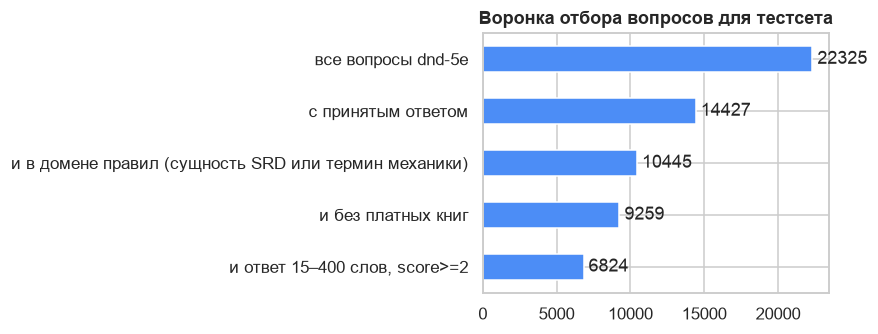

In [22]:
# Что остаётся для тестсета: вопросы с принятым ответом, строгое покрытие SRD, без платных книг, адекватная длина
cand = se[se.has_accepted & se.in_domain & ~se.paid_book & se.a_words.between(15, 400) & (se.score >= 2)]
print(f"Кандидаты для тестсета (принятый ответ + в домене правил + без платных книг + ответ 15-400 слов + score>=2): {len(cand)} из {len(se)} ({len(cand)/len(se)*100:.1f}%)")
funnel = pd.Series({
    "все вопросы dnd-5e": len(se),
    "с принятым ответом": se.has_accepted.sum(),
    "и в домене правил (сущность SRD или термин механики)": (se.has_accepted & se.in_domain).sum(),
    "и без платных книг": (se.has_accepted & se.in_domain & ~se.paid_book).sum(),
    "и ответ 15–400 слов, score>=2": len(cand),
})
ax = funnel[::-1].plot.barh(color="#4C8DF6", figsize=(8, 3.2)); ax.set_title("Воронка отбора вопросов для тестсета")
for i, v in enumerate(funnel[::-1]): ax.text(v, i, f" {v}", va="center")
save("08_se_funnel")

In [23]:
# Выбросы: примеры вопросов, где SRD не нужен (сюжет, баланс, платные книги)
out_ = se[~se.in_domain | se.paid_book | se.homebrew]
print(f"Вопросов-кандидатов в выбросы (нет ни сущности SRD, ни термина механики; или платные книги; или хоумбрю/баланс): {len(out_)} ({len(out_)/len(se)*100:.1f}%)")
random.seed(SEED)
for t in out_.sample(10, random_state=SEED)["title"]: print(" -", t)

# Утечка/цитирование: насколько ответы дословно повторяют текст SRD 2014 (8-граммы слов)
def grams(words, n=8): return {" ".join(words[i:i+n]) for i in range(len(words) - n + 1)}
srd_words = re.findall(r"[a-z0-9']+", txt14.lower().replace("’", "'"))
srd_grams = grams(srd_words)
def quotes(a):
    w = re.findall(r"[a-z0-9']+", a.lower().replace("’", "'"))
    return bool(grams(w) & srd_grams)
se["quotes_srd"] = se["a_text"].map(lambda a: quotes(a) if a else False)
print(f"\nПринятые ответы, дословно цитирующие SRD 5.1 (>=8 слов подряд): {se.quotes_srd.sum()} ({se.quotes_srd.sum()/se.has_accepted.sum()*100:.1f}% от ответов)")

Вопросов-кандидатов в выбросы (нет ни сущности SRD, ни термина механики; или платные книги; или хоумбрю/баланс): 8630 (38.7%)


 - Is D&D Beyond's full name "Dungeons & Dragons Beyond"?
 - How far away can you hear a Signal Whistle?
 - Should paying an NPC to resurrect a Zealot Barbarian be less costly?
 - What are the changes to a character caused by Wereraven Lycanthropy from the Curse of Strahd adventure?
 - Can I design my own weapons?
 - Can my familiar cast Mending on a mummy?
 - How do we transition from D&D 4e's world to D&D 5e's world?
 - How to make a handaxe return to my hand after being thrown?
 - What happens when a Paladin falls from grace?
 - Does Ethereal Sight let you discern reality from illusions?



Принятые ответы, дословно цитирующие SRD 5.1 (>=8 слов подряд): 6475 (44.9% от ответов)


**Вывод по разделу 6.** См. сводку. Важное ограничение: в этом дампе **нет вопросов про правила 2024** и нет тегов версий. Вопросы людей закрывают только версию 2014; вопросы про 2024 и про различия версий придётся строить шаблонами и по структурированным данным. Часть вопросов не относится к SRD (платные книги, сюжет), их надо отфильтровать.

## 7. Язык

Корпус английский, вопросы пользователей русские.

In [24]:
cyr = se["q_text"].str.contains(r"[А-Яа-яЁё]").mean() * 100
print(f"Вопросов SE с кириллицей: {cyr:.2f}%")
pd.DataFrame([
    ("Действие", "Action / Activity", "Action — термин, Activity — другое понятие"),
    ("Реакция", "Reaction", "Reaction vs. «реагировать» в обычной речи"),
    ("Состояние", "Condition", "Condition vs. State / Status"),
    ("Концентрация", "Concentration", "Concentration vs. Focus"),
    ("Спасбросок", "Saving throw", "Устойчивый термин, один вариант"),
    ("Контрзаклинание", "Counterspell", "Устойчивый термин; в 2014 и 2024 работает по-разному"),
], columns=["русский термин (пример)", "английский термин SRD", "комментарий"])

Вопросов SE с кириллицей: 0.02%


,русский термин (пример),английский термин SRD,комментарий
0,Действие,Action / Activity,"Action — термин, Activity — другое понятие"
1,Реакция,Reaction,Reaction vs. «реагировать» в обычной речи
2,Состояние,Condition,Condition vs. State / Status
3,Концентрация,Concentration,Concentration vs. Focus
4,Спасбросок,Saving throw,"Устойчивый термин, один вариант"
5,Контрзаклинание,Counterspell,Устойчивый термин; в 2014 и 2024 работает по-разному


**Вывод по разделу 7.** Разметка вопросов на русском в дампе отсутствует: русские вопросы придётся писать или переводить самим. Таблица выше иллюстрация (не измерение): часть терминов неоднозначна при переводе. Нужны мультиязычные эмбеддинги и словарь терминов, а качество поиска по русским запросам надо измерять отдельно.

## 8. Базовая модель: BM25

Простейший retrieval без нейросетей. Корпус: заклинания и монстры обеих версий (по одному чанку на сущность). Запросы:
- **по имени**: «What does {name} do?»;
- **по описанию**: первое предложение описания без названия сущности.

Метрики: hit@1 и hit@5 «строго» (нужная сущность **той же версии**), hit@1 «по сущности» (любая версия) и MRR. Разница между «строго» и «по сущности» показывает цену отсутствия фильтра по версии.

In [25]:
from rank_bm25 import BM25Okapi
tok = lambda s: re.findall(r"[a-z0-9']+", s.lower().replace("’", "'"))
corp = ent[ent.type.isin(["spells", "creatures"]) & (ent.words > 0)].reset_index(drop=True)
bm25 = BM25Okapi([tok(r["name"] + " " + r["text"]) for _, r in corp.iterrows()])

def first_sentence(name, text):
    t = re.sub(re.escape(name), "it", text.split("\n")[0], flags=re.I)
    s = re.split(r"(?<=[.!?])\s", t)[0]
    return s if len(s.split()) >= 6 else None

def run(kind):
    out = []
    for i, r in corp.iterrows():
        if kind == "по описанию" and r["type"] != "spells":
            continue  # у монстров первое предложение это общая черта, запрос бессмысленный
        q = f"What does {r['name']} do?" if kind == "по имени" else first_sentence(r["name"], r["text"])
        if not q: continue
        scores = bm25.get_scores(tok(q)); top = np.argsort(-scores)[:5]
        strict_rank = next((k + 1 for k, j in enumerate(top) if j == i), None)
        ent_rank = next((k + 1 for k, j in enumerate(top) if corp.loc[j, "norm"] == r["norm"] and corp.loc[j, "type"] == r["type"]), None)
        out.append({"type": r["type"], "version": r["version"], "kind": kind, "strict_rank": strict_rank, "ent_rank": ent_rank})
    return pd.DataFrame(out)

bm = pd.concat([run("по имени"), run("по описанию")], ignore_index=True)
def metr(g):
    return pd.Series({"запросов": len(g),
                      "hit@1 строго": (g.strict_rank == 1).mean(), "hit@5 строго": g.strict_rank.notna().mean(),
                      "hit@1 по сущности": (g.ent_rank == 1).mean(), "hit@5 по сущности": g.ent_rank.notna().mean(),
                      "MRR строго": (1 / g.strict_rank).fillna(0).mean()})
table = bm.groupby(["type", "kind"]).apply(metr)
display(table.round(3))
display(bm.groupby(["kind", "version"]).apply(metr).round(3))

запросов  hit@1 строго  hit@5 строго  hit@1 по сущности  hit@5 по сущности  MRR строго
type      kind                                                                                               
creatures по имени        654.0         0.495         0.991              0.887              0.997       0.724
spells    по имени        657.0         0.368         0.811              0.706              0.863       0.563
          по описанию     634.0         0.781         0.986              0.938              0.987       0.877

запросов  hit@1 строго  hit@5 строго  hit@1 по сущности  hit@5 по сущности  MRR строго
kind        version                                                                                        
по имени    2014        643.0         0.311         0.886              0.784              0.928       0.573
            2024        668.0         0.548         0.915              0.808              0.931       0.711
по описанию 2014        307.0         0.700         0.987              0.938              0.990       0.838
            2024        327.0         0.856         0.985              0.939              0.985       0.914

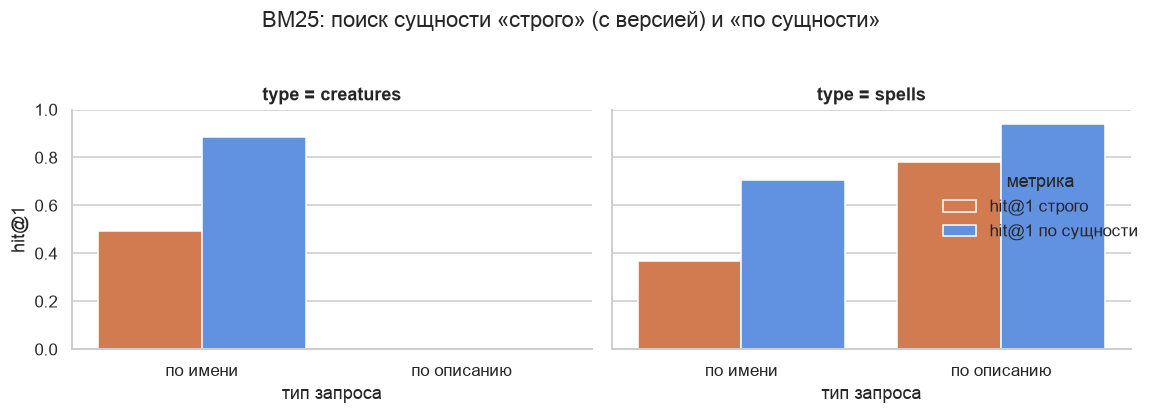

In [26]:
long = table.reset_index().melt(id_vars=["type", "kind"], value_vars=["hit@1 строго", "hit@1 по сущности"], var_name="метрика", value_name="значение")
g = sns.catplot(data=long, x="kind", y="значение", hue="метрика", col="type", kind="bar", height=3.6, aspect=1.2, palette=["#E8743B", "#4C8DF6"])
g.set_axis_labels("тип запроса", "hit@1"); g.set(ylim=(0, 1)); g.fig.suptitle("BM25: поиск сущности «строго» (с версией) и «по сущности»", y=1.04)
save("09_bm25")

**Вывод по разделу 8.** Это бейзлайн для всех следующих экспериментов (его цифры сравниваем с гибридным поиском + реранкером). Ключевое наблюдение: даже когда сущность найдена, BM25 не различает версию, поэтому «строгий» hit@1 заметно ниже «по сущности». Без метаданных версии и фильтра система будет выдавать правила не той редакции.

## 9. Аугментация и генерация данных

Для тестсета и для обучения (LoRA, RAFT) нужны вопросы с известным эталоном. Что подходит:

| Способ | Подходит? | Комментарий |
|---|---|---|
| Шаблонные вопросы по структурированным полям Open5e | да | Эталон известен по построению, дёшево |
| Генератор хоумрулов (меняет число, тип действия, добавляет исключение) | да | Ответ известен, проверяет «следуй тексту, а не памяти модели» |
| Перевод вопросов RU↔EN | да, с проверкой | Нужна выборочная проверка терминов |
| Перефразирование вопросов LLM | да, с проверкой | Эталон не должен меняться |
| Замена слов синонимами / случайное удаление слов | **нет** | Ломает точные термины («bonus action», «reaction») |
| Back-translation | ограниченно | Искажает игровые термины |

Ниже работающие прототипы двух первых способов.

In [27]:
spell14 = {norm(e["name"]): e for e in raw_entities[("2014", "spells")]}
spell24 = {norm(e["name"]): e for e in raw_entities[("2024", "spells")]}

# 1. Шаблонные вопросы с эталоном из структурированных полей
def templates(e, v):
    n = e["name"]
    ct = e.get("casting_time"); lvl = e.get("level"); conc = e.get("concentration")
    return [
        (f"What is the casting time of {n} ({v} rules)?", ct),
        (f"At what level is the spell {n} ({v} rules)?", lvl),
        (f"Does {n} require concentration ({v} rules)?", "yes" if conc else "no"),
    ]
for n in ["fireball", "counterspell"]:
    for v, d_ in [("2014", spell14), ("2024", spell24)]:
        for q, a in templates(d_[n], v): print(f"[{v}] {q}  ->  {a}")

# 2. Прототип генератора хоумрулов: меняем число кубиков урона, эталон известен по построению
def make_homerule(e, v):
    m = re.search(r"(\d+)d(\d+)", e["desc"])
    if not m: return None
    old, die = int(m[1]), m[2]; new = max(1, old - 2)
    rule = f"House rule: {e['name']} deals {new}d{die} damage instead of {old}d{die} at its base level."
    return rule, f"How much damage does {e['name']} deal at its base level?", f"{new}d{die}", f"{old}d{die}"
print()
for n in ["fireball", "lightning bolt", "cone of cold"]:
    r = make_homerule(spell14[n], "2014")
    if r: print(r[0], "\n  Q:", r[1], "\n  эталон (хоумрул):", r[2], "| память модели (SRD):", r[3])

[2014] What is the casting time of Fireball (2014 rules)?  ->  action
[2014] At what level is the spell Fireball (2014 rules)?  ->  3
[2014] Does Fireball require concentration (2014 rules)?  ->  no
[2024] What is the casting time of Fireball (2024 rules)?  ->  action
[2024] At what level is the spell Fireball (2024 rules)?  ->  3
[2024] Does Fireball require concentration (2024 rules)?  ->  no
[2014] What is the casting time of Counterspell (2014 rules)?  ->  reaction
[2014] At what level is the spell Counterspell (2014 rules)?  ->  3
[2014] Does Counterspell require concentration (2014 rules)?  ->  no
[2024] What is the casting time of Counterspell (2024 rules)?  ->  reaction
[2024] At what level is the spell Counterspell (2024 rules)?  ->  3
[2024] Does Counterspell require concentration (2024 rules)?  ->  no

House rule: Fireball deals 6d6 damage instead of 8d6 at its base level. 
  Q: How much damage does Fireball deal at its base level? 
  эталон (хоумрул): 6d6 | память модели (S

Перевод и перефразирование вопросов здесь **не проверялись на модели** (нужна LLM, это следующий этап): в таблице выше указано, подходит ли способ по свойствам задачи, а не по измеренному качеству.

## 10. Планируемый тестсет и откуда его брать

Состав тестсета из проектного плана и реальные источники для каждой категории.

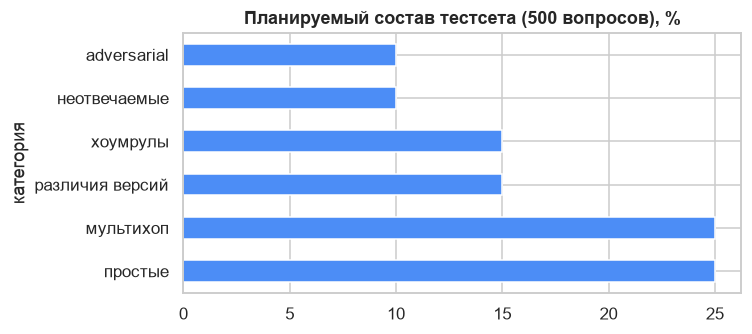

,категория,"доля, %",источник эталона
0,простые,25,Stack Exchange (часть 2014) + шаблоны Open5e
1,мультихоп,25,Stack Exchange + пути по графу правил (часть Б)
2,различия версий,15,Только шаблоны и сравнение Open5e 2014/2024 (в SE нет вопросов про 2024)
3,хоумрулы,15,Генератор хоумрулов (часть Б)
4,неотвечаемые,10,"Выдуманные сущности, контент вне SRD, платные книги"
5,adversarial,10,"Ложные посылки, смешение версий, выдуманные заклинания"


In [28]:
plan = pd.DataFrame({
    "категория": ["простые", "мультихоп", "различия версий", "хоумрулы", "неотвечаемые", "adversarial"],
    "доля, %": [25, 25, 15, 15, 10, 10],
    "источник эталона": [
        "Stack Exchange (часть 2014) + шаблоны Open5e",
        "Stack Exchange + пути по графу правил (часть Б)",
        "Только шаблоны и сравнение Open5e 2014/2024 (в SE нет вопросов про 2024)",
        "Генератор хоумрулов (часть Б)",
        "Выдуманные сущности, контент вне SRD, платные книги",
        "Ложные посылки, смешение версий, выдуманные заклинания",
    ],
})
ax = plan.set_index("категория")["доля, %"].plot.barh(color="#4C8DF6", figsize=(7, 3.2))
ax.set_title("Планируемый состав тестсета (500 вопросов), %")
save("10_testset_plan")
plan

## 11. Выводы

### 11.1. Что мы узнали о данных

**Состав и полнота.** В Open5e для двух версий SRD 3 489 сущностей. Заклинаний 319 (2014) и 339 (2024), монстров 325 и 331, классов по 24 (с подклассами). Охват типов между версиями несимметричен: *правил* (`rules`) в 2014 227, в 2024 только 56; *черт* 1 против 17; *предысторий* 1 против 4; *видов* 13 против 9; отдельных *состояний* для SRD в Open5e нет вовсе (21 запись лежит в документе `core`, то есть в 2014). Следовательно, **Open5e для 2024 подходит для заклинаний, монстров и классов, но текст правил 2024 нужно брать из PDF** (извлечён, проверен: все 339 заклинаний и 331 монстр найдены как заголовки, 516 из 519 закладок PDF совпали).

**Пропуски.** Значения вроде `damage_roll` пусты у 81% заклинаний 2014 (у остальных нет урона), это «неприменимо», а не потеря данных. Настоящие дыры: у 100% доспехов нет текста (только числовые поля), у 10,8% оружия 2014 нет текста, одно заклинание 2024 (*Greater Invisibility*) и по одному монстру в каждой версии пришли пустыми. `proficiency_bonus` у монстров 2014 пуст у 100% (поле не заполнено в источнике).

**Ошибочные значения.** Не найдено: уровни заклинаний вне 0–9, нулевые и отрицательные HP, монстры без CR, символ замены U+FFFD, неразрывные пробелы. Есть 20 дубликатов имён в рамках типа (2014) и 1 (2024), а также 57 и 12 подозрительно коротких текстов (<20 символов). Данные Open5e в целом чистые.

**Длины и чанкинг.** Окно эмбеддера 512 токенов ≈ 380 слов (оценка `слова × 1,35`, токенайзер BGE-M3 подключим позже). Заклинания (медиана 119 слов в 2014 и 102 в 2024) помещаются в окно в 94,4% и 98,2% случаев, монстры в 92,6% и 98,2%, магические предметы в 97,6–97,8%. **Классы длинные** (медиана около 665 слов, 63–67% не помещаются), правила тоже (в окно не влезает 7,9% в 2014 и 17,9% в 2024). В Markdown-корпусах разделы между заголовками в основном короткие (медиана 99 слов в 2014 и 57 в 2024; 4% и 1% разделов длиннее окна; сравнивать эти две медианы напрямую нельзя, так как заголовки в двух файлах разной детальности).

**Качество текста.** SRD 5.1 в Markdown содержит технический шум: 124 якоря `{#...}`, 3 539 Markdown-ссылок и **455 таблиц в виде HTML** (всего 30 850 HTML-тегов). Если не преобразовать таблицы, эмбеддинги будут считаться по тегам. Извлечённый из PDF Markdown 2024 чище по ссылкам, но содержит артефакт малых заглавных в таблицах характеристик монстров (`**S tr** 17 +3 +3`).

### 11.2. Две версии правил

- В двух версиях 317 общих по имени заклинаний (316 сравнимы по тексту: у *Greater Invisibility* в Open5e 2024 нет описания), ещё 2 есть только в 2014 (*Branding Smite*, *Feeblemind*) и 22 только в 2024 (*Chromatic Orb*, *Divine Smite*, *Hex*, *Tsunami* и др.). У монстров общих 283, у классов 20.
- **Текст поменялся почти везде**: медиана схожести формулировок у заклинаний 0,70, у монстров 0,39, у классов 0,28. Почти без изменений (схожесть ≥ 0,9) только 15,2% заклинаний, 0% монстров и 0% классов.
- **Но схожесть текста измеряет формулировку, а не правило.** *Fireball* имеет схожесть 0,78 при той же механике (текст переписан), а *Counterspell* 0,34 при реально изменившемся правиле (автоотмена заклинаний до 3-го уровня против спасброска Телосложения). Реально поменялись поля: время сотворения у 8,2% заклинаний, школа у 7,6%, длительность у 6,0%, дальность у 5,4%, концентрация у 2,8%. Уровень и признак ритуала не изменились ни у одного заклинания.
- Итог: **смешение версий реальная угроза**, но одним расчётом по тексту список «правило изменилось» не получить. Его придётся собирать по изменённым полям и проверять вручную (в плане это 50–75 вопросов).

### 11.3. Реальные вопросы людей (Stack Exchange)

- В дампе 22 325 вопросов с тегом `dnd-5e` (2012-01 … 2024-03), у 14 427 (64,6%) есть принятый ответ. Медиана: вопрос 139 слов, ответ 125 слов, score 8.
- **Версий в тегах нет, вопросов про правила 2024 нет вообще.** Дамп датирован апрелем 2024 (правила 2024 вышли позже), а не декабрём 2025, как было в плане проекта. Вопросы людей относятся только к версии 2014.
- Покрытие SRD (оценка по упоминанию названий): сущность SRD есть в 51,4% вопросов (строгая оценка) и в 77,4% (широкая), в заголовке в 23,5%. Термин механики (состояние, спасбросок и др.) в 45,7%. **В домене правил 71,3%** (сущность или термин). Платные книги и сеттинги упоминаются в 12,1%, теги homebrew/баланс/создание/кампания в 3,8%.
- Воронка отбора (принятый ответ → в домене → без платных книг → ответ 15–400 слов, score ≥ 2) даёт **6 824 кандидата (30,6%)**. Для тестсета 100–150 вопросов этого с запасом.
- 44,9% принятых ответов дословно цитируют SRD 5.1 (≥ 8 слов подряд): эталоны удобно сверять с текстом SRD, но это же значит, что **ответы людей нельзя брать как эталон слепо**, а вопросы и ответы скорее всего присутствовали в обучающих данных LLM (гипотеза, не измерено): базовая LLM без контекста может выглядеть лучше, чем на новых вопросах.
- Кириллица в вопросах: 0,02%. Русских вопросов в дампе нет.
- Ограничения оценок: сопоставление по названиям даёт приблизительную долю (короткие названия вроде *Light*, *Fly* совпадают с обычными словами, а общие вопросы без названий вроде «Can my familiar cast Mending on a mummy?» могут не попасть в «домен»). Это оценки порядка величины, а не точные проценты.

### 11.4. Базовая модель: BM25

- Заклинания, запрос «What does X do?»: hit@1 «строго» (сущность **и версия**) **0,37**, а «по сущности» (любая версия) **0,71**. Разрыв 34 п.п. возникает потому, что у большинства сущностей в корпусе два почти одинаковых по словам чанка (2014 и 2024), а запрос версию не содержит. hit@5 строго 0,81.
- Запросы по описанию (первое предложение без названия): hit@1 строго 0,78, по сущности 0,94, hit@5 строго 0,99.
- Монстры по имени: hit@1 строго 0,50, по сущности 0,89.
- Вывод: **версия обязана быть метаданными и фильтром (или явной частью запроса)**; BM25 без них находит нужное правило, но в половине случаев из не той редакции. Эти числа бейзлайн: гибридный поиск (dense + sparse) с реранкером и фильтром по версии должен их превзойти.
- Ограничения: запросы только английские; русские запросы не проверялись. Чанк это сущность целиком, без чанкинга по подзаголовкам.

### 11.5. Решения для пайплайна

| # | Наблюдение | Решение |
|---|---|---|
| 1 | Заклинания, монстры, предметы в окно 512 токенов помещаются в ≥ 92% | Чанк = сущность для них. Классы и длинные правила резать по подзаголовкам, с родительским заголовком в метаданных |
| 2 | В SRD 5.1 Markdown 455 HTML-таблиц, 3 539 ссылок, 124 якоря | Очистка: HTML-таблицы в текст, ссылки и якоря убрать |
| 3 | BM25: hit@1 строго 0,37 против 0,71 по сущности | Метаданные `version`, фильтр по версии в Qdrant, версия определяется роутером или выбирается пользователем. Отчитываться по обеим метрикам |
| 4 | Open5e по 2024 неполон (правил 56 против 227, состояний нет) | Текст правил 2024 из PDF, структурные поля из Open5e; состояния 2014 из Open5e, 2024 из PDF |
| 5 | Схожесть текста не равна изменению правила | Список «правило изменилось» строить по изменённым полям + ручная проверка 50–75 пар; вопросы категории «различия версий» только из него |
| 6 | В SE нет вопросов про 2024; 6 824 кандидата по 2014 | Вопросы людей только для категорий «простые» и «мультихоп» в версии 2014. Для 2024, версий и хоумрулов шаблоны Open5e и генератор. Эталоны SE: черновик LLM + ручная проверка выборки |
| 7 | Ответы SE на 44,9% цитируют SRD; возможно присутствие в обучении LLM | Не использовать ответ SE как эталон без сверки с SRD; для базовой LLM добавить вопросы, которых нет в SE (шаблонные, свежие) и учесть смещение |
| 8 | В дампе нет русских вопросов | Русские вопросы получать переводом/переписыванием + ручная проверка терминов; точность поиска на RU и EN измерять отдельно |
| 9 | 71,3% вопросов SE в домене правил, 12,1% про платные книги | Фильтры по платным книгам и домену применять в пайплайне отбора; платные книги переиспользовать как «неотвечаемые» (10% тестсета) |

### 11.6. Практическая применимость

Отдельный документ: [reports/practical_value.md](reports/practical_value.md). Кратко: проект решает проблему игроков и мастеров, которым нужны точные ответы по правилам с учётом версии; главные риски (охват SRD, устаревание, доверие к ответу, русский язык, хоумрулы) описаны там с оценкой серьёзности и способами проверки качества со стороны заказчика.

### 11.7. Ограничения этого анализа и что дальше

- Оценка токенов приблизительная; токенайзер BGE-M3 подключим при построении индекса.
- Покрытие SRD и «домен» оценены по упоминаниям слов; точные цифры будут после разметки выборки вручную.
- BM25 проверен только на английских запросах и только на заклинаниях и монстрах.
- Перевод и перефразирование (раздел 9) не проверялись на модели.
- Дамп Stack Exchange старый (апрель 2024); если появится более новый с тегами версий, пересчитаем разделы 6 и 11.3.
- **Следующий чекпойнт (простые модели):** выбор метрики (hit@k, MRR, RAGAS), первый RAG (BM25 + dense + фильтр по версии), бейзлайн «LLM без контекста», сравнение на тестсете v1.